# Variance Budget: Position Signal vs Re-Placement vs Repeat Noise

**Question:** two captures of the same object with the same speaker differ for three reasons: the object moved (signal), the setup changed between layouts (the object was picked up and put down again, the box or speaker rack got nudged, time passed), and recording twice is never identical (repeat noise). How big is each, in gastro and cardboard? A preprocessing step helps only if it raises signal relative to the other two.

Builds on: nb53/nb54 (the nuisances are a gain per capture and a gain per laser; ICC), nb88 (empty box changes over a session; speaker R² 0.88), nb96 §10 (placing an object knocks the box below 90 Hz, seen by speaker 1), nb99 (`move / noise`), nb100 (Tukey > Hann).

**One tool: the variogram.** For two captures `a`, `b` with the same box, speaker and object, and a feature `x` (one laser, band, axis):

```
γ(a, b) = ½ (x_a − x_b)²        # half squared difference; for pure noise, E γ = noise variance
```

| term | measured from | means |
|---|---|---|
| repeat `R` | empty box, same layout (seconds apart) | recording twice, nothing touched |
| later layout `L` | object pairs at nearly the same spot, one layout later (20-75 min) | re-placement + whatever changed in the setup |
| signal `S` | object pairs far apart, at the same time gap | the object moving |

There are no back-to-back repeats with an object in place, so an object's own repeat noise can't be measured; `R` is the empty box's.

Data: single-object layouts of the 4 main objects (cube, candle, vase, soap dispenser) and the empty box, speakers 1/3/5/7. Excluded: two-object, cylinder, glass-cup, rotated, sideways, lid, laser-shift, unseen-speaker, and the cardboard **random-pose cube** layouts (random orientation; section 7 uses them on their own). Gastro's candle and vase are one layout each. Features: |FFT| (Tukey window, nb100) averaged into 117 bands of 7.7 Hz, per laser and axis: 100 × 117 × 2 = 23 400 per capture. Runtime ~6 min.

# 1 Setup

In [1]:
import os
os.environ["OPENBLAS_NUM_THREADS"] = "4"
import json
import warnings
from concurrent.futures import ProcessPoolExecutor
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from scipy.signal import butter, sosfiltfilt
from scipy.signal.windows import tukey

REPO = Path.cwd().parent
BOXES = dict(gastro="2026_09_27_gastronorm_four_objs", cardboard="2026_10_11_cardboard_four_objs")
OBJS = {"red-cube": "cube", "candle": "candle", "vase": "vase", "soap dispenser": "soap"}
SKIP = ("shift", "lid", "rotat", "speaker", "sideways", "random")   # "random": the random-orientation cube layouts (section 7)
COLORS = dict(gastro="#2a78d6", cardboard="#1baf7a")
warnings.filterwarnings("ignore")

FPS, NT = 2500, 3250
fr = np.fft.rfftfreq(NT, 1 / FPS); inband = (fr >= 100) & (fr <= 1000)
fb = fr[inband].reshape(117, 10).mean(1)
sos = butter(5, [100, 1000], fs=FPS, btype="band", output="sos")
TUKEY = tukey(NT, 0.02)

def meta(p): return {k: v for l in p.read_text().splitlines() if l.strip() for k, v in json.loads(l).items()}

def capture(d):   # band-averaged |X| for both windows: (100 lasers, 117 bands, 2 axes)
    x = sosfiltfilt(sos, np.load(d / "vibration/02_raw_shifts.npy"), axis=1)
    A = dict(hann=np.abs(np.load(d / "vibration/04_ffts.npz")["fft"][0]), tukey=np.abs(np.fft.rfft(x * TUKEY[None, :, None], axis=1)[:, inband]))
    return {k: a.reshape(100, 117, 10, 2).mean(2).astype(np.float32) for k, a in A.items()}

rows = []
for box, e in BOXES.items():
    for p in sorted((REPO / "experiments" / e / "samples").glob("*/metadata.jsonl")):
        m = meta(p)
        obj = OBJS.get(next(iter(m["objects"]))) if m.get("n_objects") == 1 else ("empty" if m.get("is_empty_box") else None)
        if obj is None or m["speaker"] not in (1, 3, 5, 7) or any(k in m["layout"] for k in SKIP): continue
        com = m["avg_com"] if obj != "empty" else [np.nan, np.nan]
        rows.append(dict(box=box, obj=obj, layout=m["layout"], pos=m["position_id"], spk=m["speaker"], t=pd.Timestamp(m["timestamp"]),
                         row=com[0], col=com[1], size=np.sqrt(m["crop_overhead_shape"][0] * m["crop_overhead_shape"][1]), dir=p.parent))
df = pd.DataFrame(rows)
df["t"] = df.groupby("box").t.transform(lambda t: (t - t.min()).dt.total_seconds() / 60)   # minutes since the box's first capture
with ProcessPoolExecutor(24) as ex: res = list(ex.map(capture, df.dir, chunksize=8))
MAG = {k: np.stack([r[k] for r in res]) for k in ("hann", "tukey")}                         # (captures, 100, 117, 2)
del res
df.groupby(["box", "obj"]).agg(captures=("pos", "size"), positions=("pos", "nunique"), hours=("t", lambda t: round((t.max() - t.min()) / 60, 1))).unstack(0)

captures        positions            hours       
box    cardboard gastro cardboard gastro cardboard gastro
obj                                                      
candle      1156    780       289    260       1.0    2.0
cube         816    843       204    281       0.7    1.6
empty         76     36        19     12       4.9    6.5
soap        1088    735       272    245       0.8    1.2
vase        1028    804       257    268       0.9    1.0

# 2 Positions Were Recorded as a Scan

If consecutive captures are close in space, time and position are confounded: anything that changes slowly over time looks like position, and a correction that removes slow changes over time (a rolling baseline) would remove position too.

`step` = how far the object moved between consecutive captures (fraction of the box size), against randomly ordered captures. Plot: the cube's positions (speaker 1), colored by capture time.

step           random       
box    cardboard gastro cardboard gastro
obj                                     
candle     0.067  0.058     0.329  0.300
cube       0.069  0.068     0.428  0.344
soap       0.065  0.074     0.407  0.346
vase       0.073  0.037     0.389  0.350

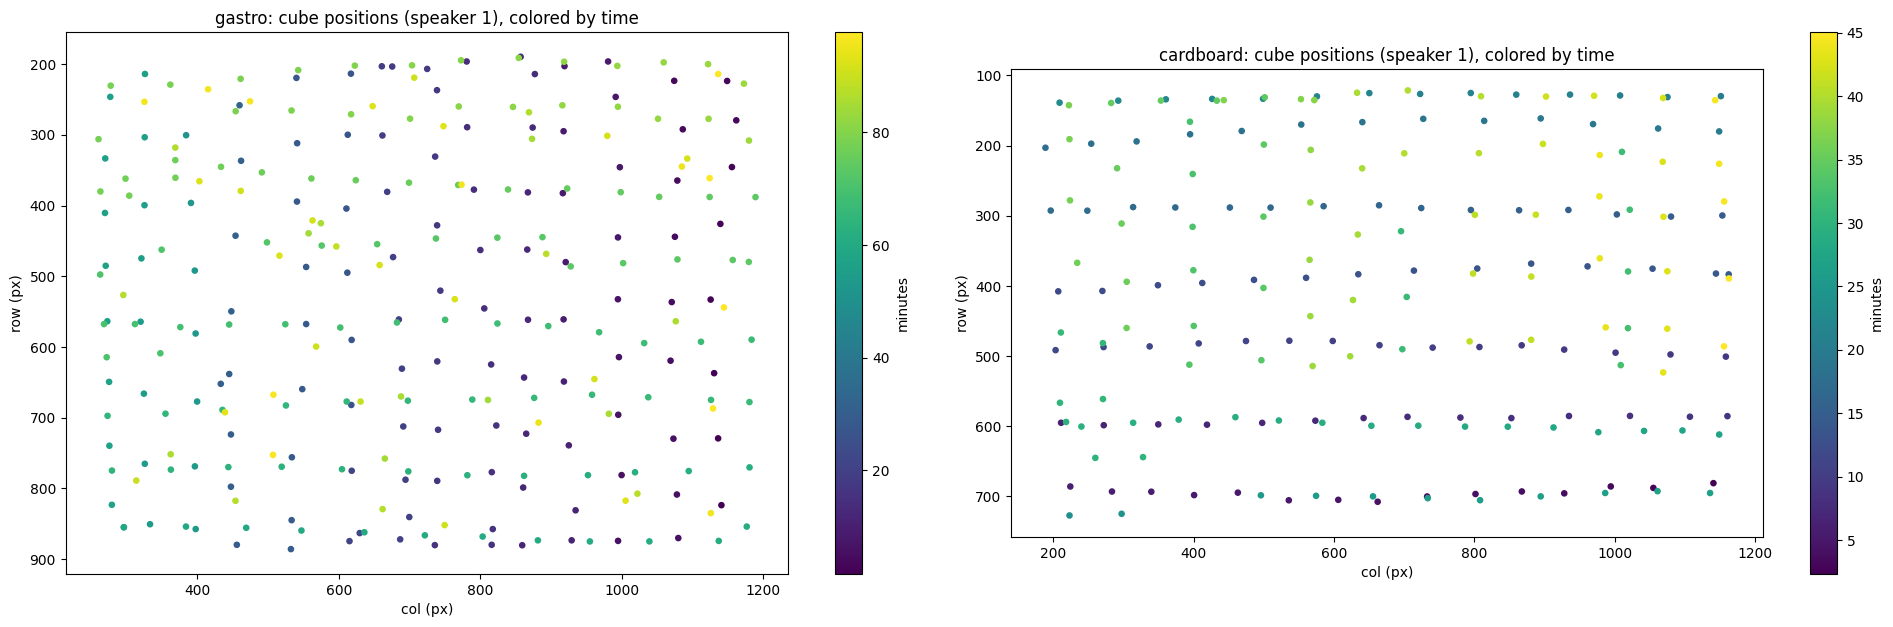

In [2]:
rows = []
for (box, obj), g in df[(df.obj != "empty") & (df.spk == 1)].sort_values("t").groupby(["box", "obj"]):
    xy = g[["row", "col"]].to_numpy(float) / g["size"].to_numpy()[:, None]
    rows.append(dict(box=box, obj=obj, step=np.median(np.linalg.norm(np.diff(xy, axis=0), axis=1)),
                     random=np.median(np.linalg.norm(xy - xy[np.random.default_rng(0).permutation(len(xy))], axis=1))))
fig, axs = plt.subplots(1, 2, figsize=(20, 6))
for ax, box in zip(axs, BOXES):
    g = df[(df.box == box) & (df.obj == "cube") & (df.spk == 1)]
    s = ax.scatter(g.col, g.row, c=g.t, cmap="viridis", s=14)
    ax.set(title=f"{box}: cube positions (speaker 1), colored by time", xlabel="col (px)", ylabel="row (px)", aspect="equal")
    ax.invert_yaxis(); plt.colorbar(s, ax=ax, label="minutes")
plt.tight_layout()
pd.DataFrame(rows).pivot(index="obj", columns="box").round(3)

**Reading:** - Consecutive captures are 0.04-0.08 of the box apart, random pairs 0.30-0.41: every layout is recorded as a scan, and the layouts one after another (the plot: early grids dark, later ones fill in between).
- So within a layout, time and position move together. The later layouts revisit nearby positions 20-75 min later; those pairs are what separates time from position in section 4.
- Consequence: a rolling baseline over time would remove position signal along with any slow change in the setup. Don't use one.

# 3 The Pairs and the Fit

All same-speaker pairs: empty-box pairs (same layout = seconds apart; different layouts = 0.4-6.5 h apart), and object pairs (same object), each with its time gap `Δt` and position gap `Δpos` (distance between the object's centres, as a fraction of the box size `sqrt(H·W)`, ~1100-1230 px).

Because of the scan (section 2), far-apart pairs are also far apart in time, so `γ` vs `Δpos` alone mixes the two. The object pairs are binned by `Δt` and `Δpos`, and the bin means fitted, per feature, as

```
γ(Δt bin, Δpos bin) = a(Δt) + b(Δpos),      b(nearest Δpos bin) = 0       # least squares, weighted by pairs per bin
```

so `a(Δt)` is what two captures of nearly the same spot look like Δt apart, and `b(Δpos)` is the extra difference from moving the object, at a fixed time gap. Then:

```
R    = γ of empty, same-layout pairs                       # repeat noise
N    = a(Δt) averaged over the session's pairs             # "the same spot, recorded again": the effective floor
L    = N − a(Δt < 5 min)                                   # later layout: how much N grows beyond a few minutes
X    = a(Δt < 5 min) − R                                   # short-gap excess: spots up to 5% of the box apart, minutes apart
S    = b(Δpos ≥ 0.3)                                       # signal: moving the object across the box
```

`N = R + X + L`. Pairs more than a few minutes apart are almost always from different layouts, so `L` mixes re-placement (orientation, exact spot) with anything that changed in the setup. Sections 6-9 take it apart.

In [3]:
T_EDGES = [0, 5, 15, 30, 60, 120, np.inf]     # minutes
POS_EDGES = [0, .05, .1, .2, .3, np.inf]      # fraction of the box size
MAX_PAIRS = 3000

rows = []
for (box, obj, spk), g in df.groupby(["box", "obj", "spk"]):
    i, j = np.triu_indices(len(g), 1)
    a, b = g.iloc[i], g.iloc[j]
    rows.append(pd.DataFrame(dict(box=box, obj=obj, spk=spk, i=g.index[i], j=g.index[j], dt=np.abs(a.t.to_numpy() - b.t.to_numpy()),
                                  dpos=np.hypot(a.row.to_numpy() - b.row.to_numpy(), a.col.to_numpy() - b.col.to_numpy()) / a["size"].to_numpy(),
                                  same_layout=a.layout.to_numpy() == b.layout.to_numpy())))
pairs = pd.concat(rows, ignore_index=True)
pairs["tb"] = pd.cut(pairs.dt, T_EDGES, right=False, labels=False)
pairs["pb"] = pd.cut(pairs.dpos, POS_EDGES, right=False, labels=False)

def gamma(X, i, j, chunk=2000):   # mean over the pairs of ½ (x_i − x_j)², per feature
    return sum(((X[i[k:k + chunk]] - X[j[k:k + chunk]]) ** 2).sum(0) for k in range(0, len(i), chunk)) / (2 * len(i))

def budget(X, box):               # X: (all captures, features)
    p = pairs[pairs.box == box]
    e, o = p[p.obj == "empty"], p[p.obj != "empty"]
    o = o.sample(frac=1, random_state=0).groupby(["tb", "pb"]).head(MAX_PAIRS)   # ≤ 3000 random pairs per bin: plenty for a mean, 5x faster
    cells = o.groupby(["tb", "pb"])
    key, n = np.array(list(cells.groups)).astype(int), cells.size().to_numpy()
    G = np.stack([gamma(X, g.i.to_numpy(), g.j.to_numpy()) for _, g in cells])                        # (bins, features)
    nt, npb = len(T_EDGES) - 1, len(POS_EDGES) - 1
    A = np.hstack([np.eye(nt)[key[:, 0]], np.eye(npb)[key[:, 1]][:, 1:]])                              # a(Δt) + b(Δpos)
    coef = np.linalg.lstsq(A * np.sqrt(n)[:, None], G * np.sqrt(n)[:, None], rcond=None)[0]
    a, b = coef[:nt], np.vstack([np.zeros(X.shape[1]), coef[nt:]])
    w = p[p.obj != "empty"].groupby("tb").size().reindex(range(nt), fill_value=0).to_numpy()
    R = gamma(X, e.i[e.same_layout].to_numpy(), e.j[e.same_layout].to_numpy())
    N = (w[:, None] * a).sum(0) / w.sum()
    return dict(R=R, N=N, L=N - a[0], X=a[0] - R, S=b[-1], a=a, b=b, w=w, E=gamma(X, e.i[~e.same_layout].to_numpy(), e.j[~e.same_layout].to_numpy()),
                bins=pd.DataFrame(dict(tb=key[:, 0], pb=key[:, 1], pairs=n, gamma=G.mean(1))))

pairs.assign(kind=np.where(pairs.obj == "empty", np.where(pairs.same_layout, "empty, same layout", "empty, other layout"), "object")).groupby(["box", "kind"]).agg(
    pairs=("dt", "size"), dt_median_min=("dt", "median")).round(1)

pairs  dt_median_min
box       kind                                      
cardboard empty, other layout     600          110.7
          empty, same layout       84            0.3
          object               528296           14.9
gastro    empty, other layout     162          195.0
          empty, same layout       36            0.3
          object               416034           23.5

# 4 The Budget, in dB

Features in dB (`20 log10 |X|`, Tukey): the per-capture and per-laser gains of nb53 become additive, and `γ` is in dB². Numbers are means over the 23 400 features.

,gastro,cardboard
R: repeat,0.633,1.128
X: short-gap excess,0.827,0.477
L: later layout,0.517,0.841
N = R + X + L,1.977,2.446
"empty, other layout − R (hours)",1.197,2.864
S: signal,2.347,2.879
S / N,1.187,1.177


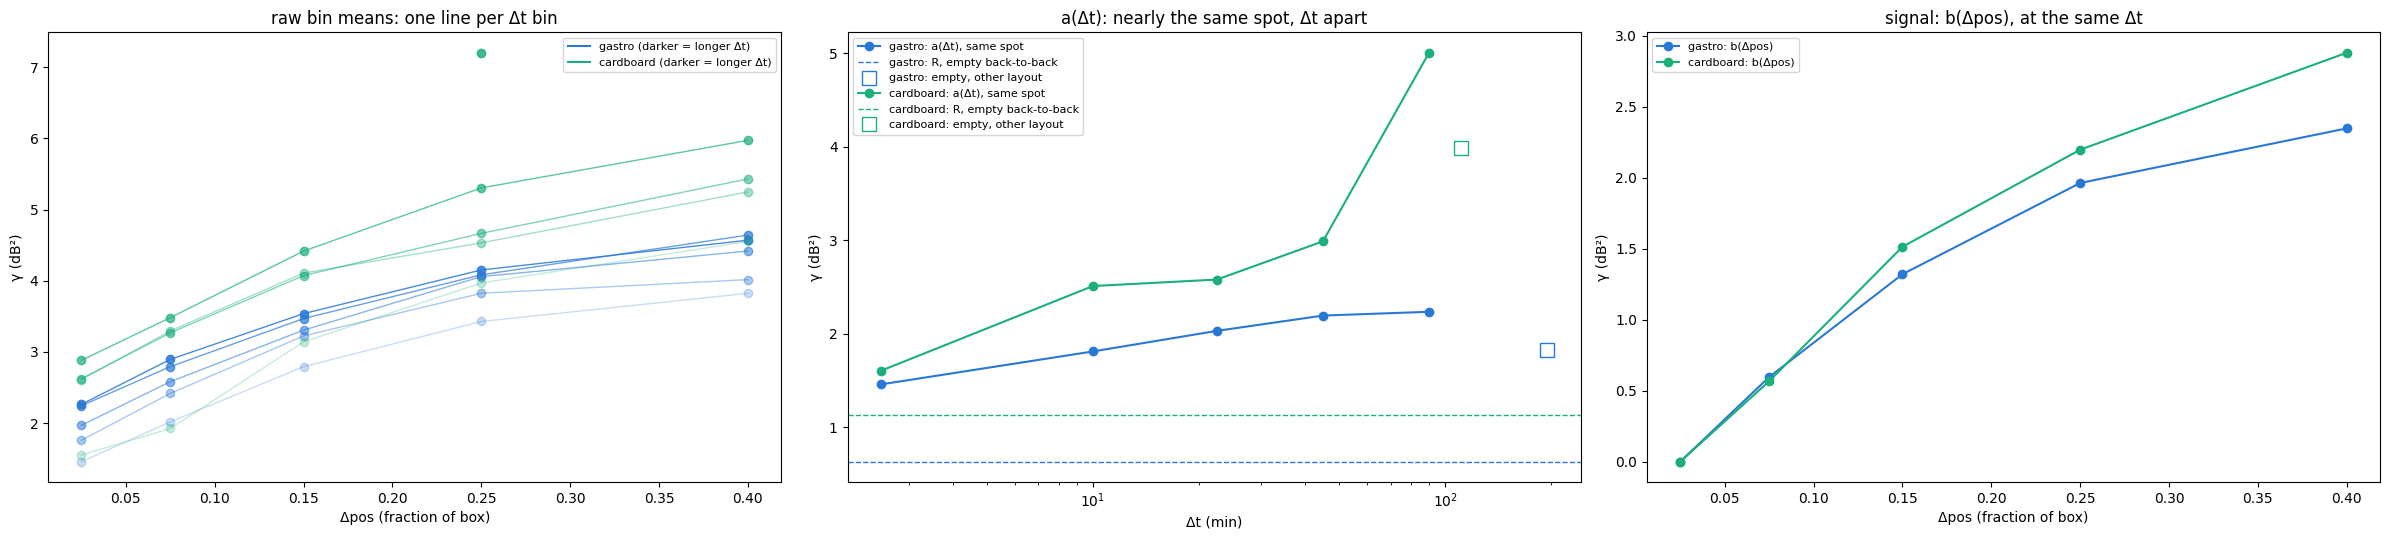

In [4]:
DB = 20 * np.log10(MAG["tukey"].reshape(len(df), -1))
B = {box: budget(DB, box) for box in BOXES}

tc = [(T_EDGES[k] + min(T_EDGES[k + 1], 240)) / 2 for k in range(len(T_EDGES) - 1)]
pc = [(POS_EDGES[k] + min(POS_EDGES[k + 1], .5)) / 2 for k in range(len(POS_EDGES) - 1)]
fig, axs = plt.subplots(1, 3, figsize=(24, 5.5))
for box, r in B.items():
    for tb, g in r["bins"].groupby("tb"):
        axs[0].plot([pc[k] for k in g.pb], g.gamma, "o-", c=COLORS[box], alpha=.25 + .75 * tb / (len(T_EDGES) - 2), lw=1)
    axs[0].plot([], [], c=COLORS[box], label=f"{box} (darker = longer Δt)")
    m = r["w"] > 0                                                         # Δt bins with object pairs
    axs[1].plot(np.array(tc)[m], r["a"].mean(1)[m], "o-", c=COLORS[box], label=f"{box}: a(Δt), same spot")
    axs[1].axhline(r["R"].mean(), c=COLORS[box], ls="--", lw=1, label=f"{box}: R, empty back-to-back")
    e = pairs[(pairs.box == box) & (pairs.obj == "empty") & ~pairs.same_layout]
    axs[1].plot(e.dt.median(), r["E"].mean(), "s", c=COLORS[box], ms=10, mfc="none", label=f"{box}: empty, other layout")
    axs[2].plot(pc, r["b"].mean(1), "o-", c=COLORS[box], label=f"{box}: b(Δpos)")
axs[0].set(xlabel="Δpos (fraction of box)", ylabel="γ (dB²)", title="raw bin means: one line per Δt bin")
axs[1].set(xlabel="Δt (min)", ylabel="γ (dB²)", xscale="log", title="a(Δt): nearly the same spot, Δt apart")
axs[2].set(xlabel="Δpos (fraction of box)", ylabel="γ (dB²)", title="signal: b(Δpos), at the same Δt")
for ax in axs: ax.legend(fontsize=8)
plt.tight_layout()
pd.DataFrame({box: {"R: repeat": r["R"].mean(), "X: short-gap excess": r["X"].mean(), "L: later layout": r["L"].mean(), "N = R + X + L": r["N"].mean(),
                    "empty, other layout − R (hours)": (r["E"] - r["R"]).mean(), "S: signal": r["S"].mean(), "S / N": r["S"].mean() / r["N"].mean()} for box, r in B.items()}).round(3)

**Reading:** - **Repeat noise is the smallest term.** Back-to-back empty captures differ by R = 0.63 dB² (gastro) and 1.13 (cardboard). The same object at nearly the same spot, recorded again later in the session, differs by N = 2.0 and 2.4: **3.1× and 2.2× R.**
- **It grows with the time gap.** At a fixed position gap, `a(Δt)` rises from minutes to an hour (gastro 1.5 → 2.2 dB²). Pairs more than a few minutes apart come from different layouts, so this mixes re-placing the object with anything that changed in the setup; sections 6-8 separate them. The empty box, with nothing placed, also changes over hours: +1.2 (gastro) and +2.9 (cardboard) dB² above its repeat noise.
- **The signal barely clears the floor.** Moving the object across the box (Δpos ≥ 0.3) adds S = 2.3 (gastro) and 2.9 (cardboard) dB², only **1.19× and 1.18× N**.
- `b(Δpos)` rises steadily up to a quarter of the box, then flattens.

# 5 Where in Frequency

The same terms per band (mean over lasers and axes). Where `S` sits above `N`, a band carries position beyond re-recording. The table adds `S / N` per band.

gastro                   cardboard                  
                 R     N     S S / N         R     N     S S / N
100-150 Hz    0.66  1.88  2.20  1.17      0.14  1.83  1.83  1.00
150-300 Hz    0.33  1.39  1.68  1.21      0.30  1.53  1.19  0.78
300-700 Hz    0.69  2.15  2.18  1.01      1.27  2.31  2.44  1.06
700-1000 Hz   0.71  2.05  2.94  1.43      1.52  3.19  4.49  1.41

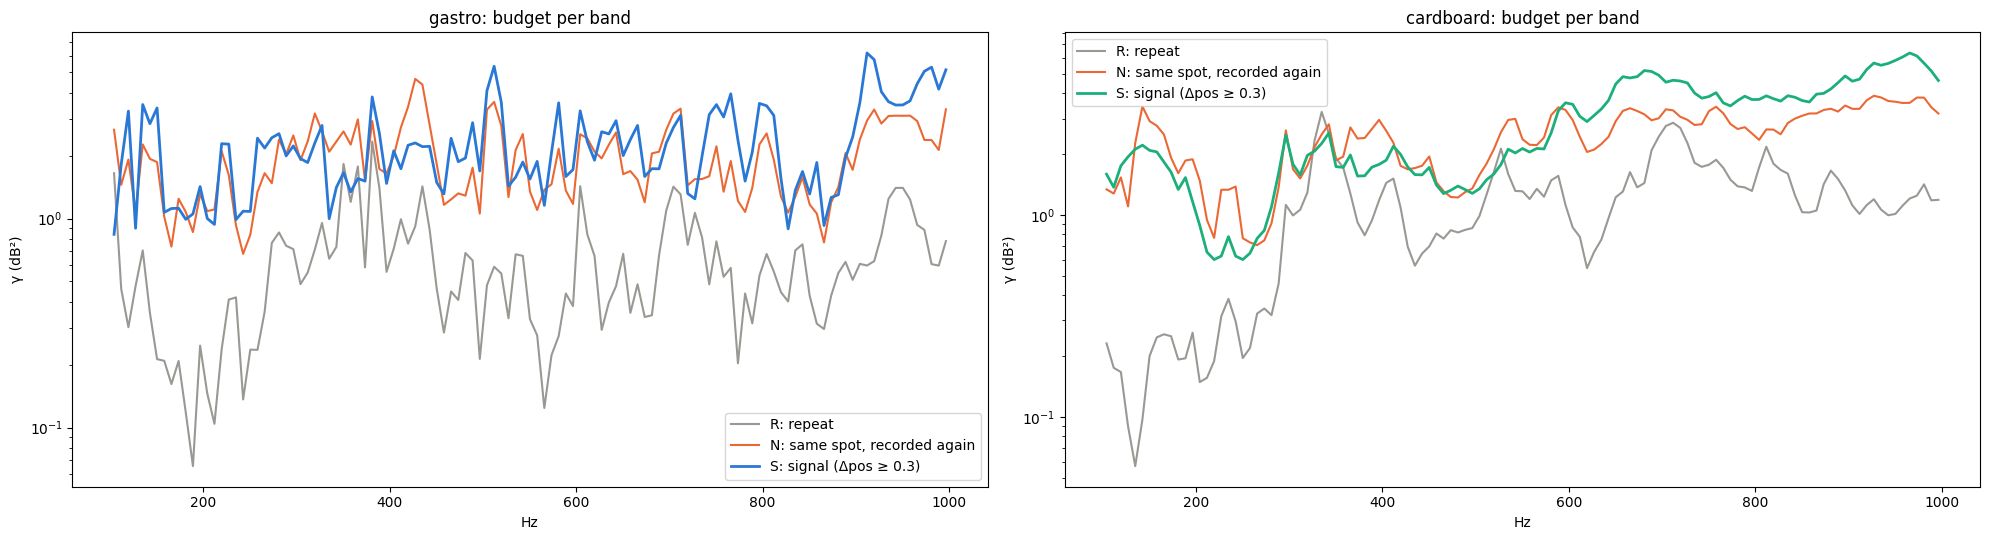

In [5]:
def per_band(v): return v.reshape(100, 117, 2).mean((0, 2))
fig, axs = plt.subplots(1, 2, figsize=(20, 5.5))
for ax, (box, r) in zip(axs, B.items()):
    ax.plot(fb, per_band(r["R"]), c="#9a9893", label="R: repeat")
    ax.plot(fb, per_band(r["N"]), c="#eb6834", label="N: same spot, recorded again")
    ax.plot(fb, per_band(r["S"]), c=COLORS[box], lw=2, label="S: signal (Δpos ≥ 0.3)")
    ax.set(xlabel="Hz", ylabel="γ (dB²)", yscale="log", title=f"{box}: budget per band")
    ax.legend()
plt.tight_layout()
RANGES = [(100, 150), (150, 300), (300, 700), (700, 1000)]
t = pd.DataFrame({(box, k): [per_band(r[k])[(fb >= lo) & (fb < hi)].mean() for lo, hi in RANGES] for box, r in B.items() for k in ("R", "N", "S")},
                 index=[f"{lo}-{hi} Hz" for lo, hi in RANGES])
for box in BOXES: t[box, "S / N"] = t[box, "S"] / t[box, "N"]
t[[(b, k) for b in BOXES for k in ("R", "N", "S", "S / N")]].round(2)

**Reading:** - **The best band is 700-1000 Hz in both boxes**: S / N = 1.43 (gastro) and 1.41 (cardboard), against 1.0-1.2 elsewhere. It does not rise steadily with frequency: cardboard is worst at 150-300 Hz (0.78) and gastro's second-best band is 100-150 Hz (1.17). The edge is modest, and this is one session per box in 4 coarse bands.
- **`N` is above `R` in every band**, so no band is limited by repeat noise.
- **Cardboard below 300 Hz:** the repeat noise is tiny (0.14-0.30 dB²) but `N` is 1.5-1.8: almost all of the floor there comes from later layouts, and S ≤ N.

# 6 How Close Is "the Same Spot"?

Section 4's nearest bin spans 0-5% of the box. Here the same `γ` (mean over features, per pair) in finer bins of `Δpos`, split by whether the two captures come from the same layout (recorded minutes apart, nothing re-placed in between) or different layouts (the object was put down again, 20-75 min later). Dashed: `R`. 1% of the box ≈ 11-12 px.

R (empty, back-to-back): {'gastro': np.float32(0.63), 'cardboard': np.float32(1.13)}


0.00-0.01  0.01-0.02  0.02-0.03  0.03-0.05  \
box       obj    layouts                                                    
cardboard candle later layout       2.59       2.65       2.80       3.04   
                 same layout        3.11       2.53       2.18       2.28   
          cube   later layout       1.33       1.34       1.41       1.45   
                 same layout        0.89       0.59       0.64       1.26   
          soap   later layout       2.61       2.78       2.72       2.78   
                 same layout         NaN        NaN       2.95       1.70   
          vase   later layout       2.74       2.55       2.70       3.06   
                 same layout         NaN       1.27       1.46       1.75   
gastro    candle same layout        1.38       1.64       1.81       1.98   
          cube   later layout       2.50       2.69       2.77       2.84   
                 same layout         NaN       1.27       1.45       1.75   
          soap   later layout       1.26       1.48       1.57       1.80   
                 same layout        0.76        NaN       1.29       1.63   
          vase   same layout        1.48       1.01       1.26       1.49   

                               0.05-0.10  0.10-0.30  0.30-1.00  
box       obj    layouts                                        
cardboard candle later layout       3.65       5.25       6.24  
                 same layout        2.49       4.66       6.19  
          cube   later layout       1.73       2.30       3.11  
                 same layout        1.14       2.02       2.89  
          soap   later layout       3.30       4.43       4.94  
                 same layout        2.25       3.83       4.97  
          vase   later layout       3.57       4.88       6.11  
                 same layout        2.03       3.88       5.93  
gastro    candle same layout        2.52       3.83       4.59  
          cube   later layout       3.20       3.88       4.39  
                 same layout        1.85       2.97       3.80  
          soap   later layout       2.32       3.35       3.73  
                 same layout        2.03       3.18       3.74  
          vase   same layout        2.23       3.80       4.94

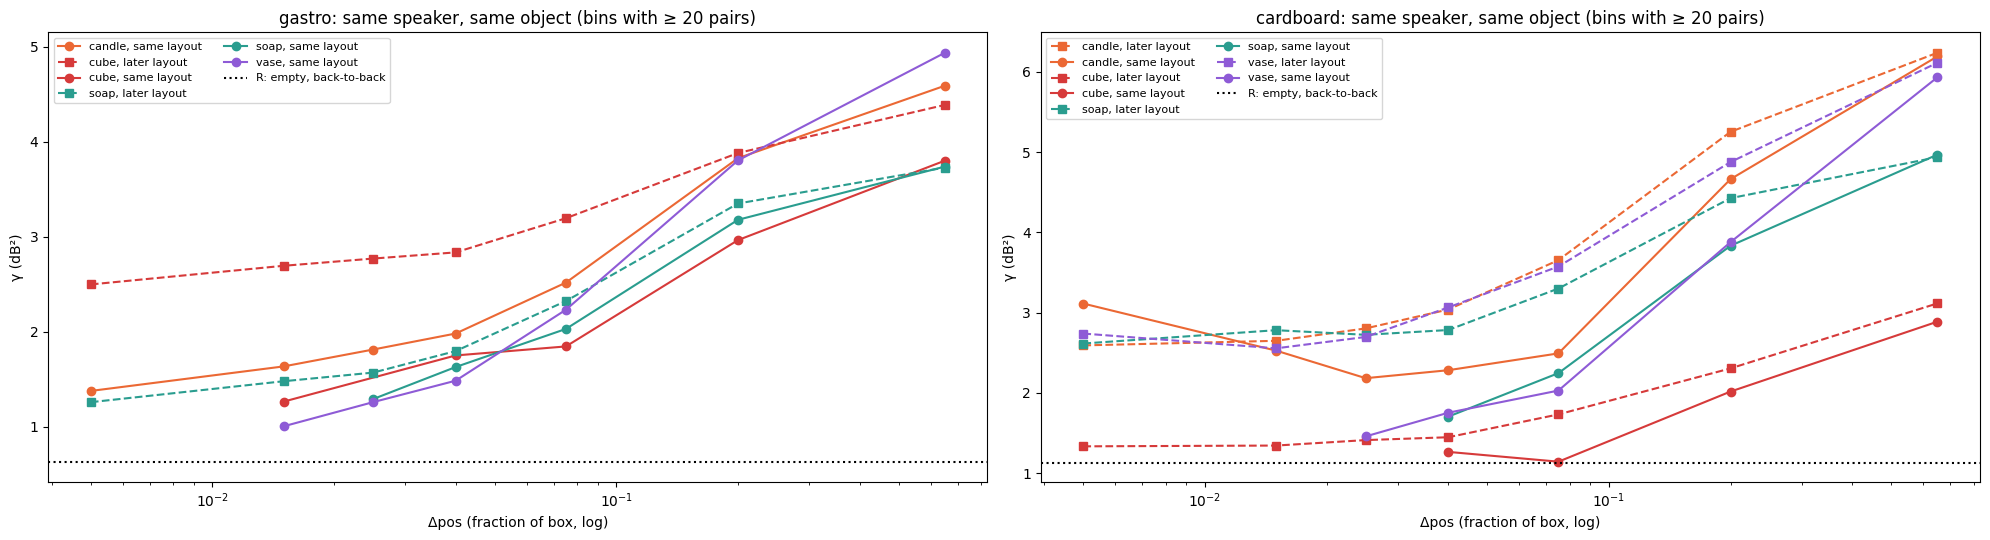

In [6]:
FINE = [0, .01, .02, .03, .05, .1, .3, 1]
def pair_gamma(X, I, J, chunk=2000):   # per pair: ½ (x_i − x_j)², averaged over features
    return np.concatenate([0.5 * ((X[I[k:k + chunk]] - X[J[k:k + chunk]]) ** 2).mean(1) for k in range(0, len(I), chunk)])

o = pairs[pairs.obj != "empty"].assign(layouts=lambda d: np.where(d.same_layout, "same layout", "later layout"), d=lambda d: pd.cut(d.dpos, FINE, right=False))
n_pairs = o.groupby(["box", "obj", "layouts", "d"], observed=True).size()
o = o.sample(frac=1, random_state=0).groupby(["box", "obj", "layouts", "d"], observed=True).head(1500)
o["g"] = pair_gamma(DB, o.i.to_numpy(), o.j.to_numpy())
fine = o.groupby(["box", "obj", "layouts", "d"], observed=True).g.mean()
R_pair = {box: pair_gamma(DB, *pairs[(pairs.box == box) & (pairs.obj == "empty") & pairs.same_layout][["i", "j"]].to_numpy().T).mean() for box in BOXES}

mid = [(FINE[k] + FINE[k + 1]) / 2 for k in range(len(FINE) - 1)]
OBJ_COLORS = dict(candle="#eb6834", vase="#8e5bd6", cube="#d63a3a", soap="#2a9d8f")
fig, axs = plt.subplots(1, 2, figsize=(20, 5.5))
for ax, box in zip(axs, BOXES):
    for (obj, lay), s in fine[box].groupby(level=[0, 1]):
        s = s[n_pairs[box][obj][lay].reindex(s.index.get_level_values("d")).to_numpy() >= 20]
        ax.plot([mid[FINE.index(iv.left)] for iv in s.index.get_level_values("d")], s.to_numpy(), "o-" if lay == "same layout" else "s--", c=OBJ_COLORS[obj], label=f"{obj}, {lay}")
    ax.axhline(R_pair[box], c="k", ls=":", label="R: empty, back-to-back")
    ax.set(xscale="log", xlabel="Δpos (fraction of box, log)", ylabel="γ (dB²)", title=f"{box}: same speaker, same object (bins with ≥ 20 pairs)")
    ax.legend(fontsize=8, ncol=2)
plt.tight_layout()
show_fine = fine.unstack("d").round(2)
show_fine.columns = [f"{iv.left:.2f}-{iv.right:.2f}" for iv in show_fine.columns]
print("R (empty, back-to-back):", {b: round(v, 2) for b, v in R_pair.items()})
show_fine

**Reading:** - **Stricter matching lowers the floor but never reaches `R`.** Within the same layout, gastro's objects at 1-3% of the box differ by 1.0-1.8 dB² against R = 0.63; cardboard's vase and soap at 2-5% by 1.5-1.8 against R = 1.13. Even at under 1% of the box, two captures are not repeats.
- **A later layout adds a jump at every distance**, for most objects: cardboard's vase at 1-3% goes from 1.3-1.5 (same layout) to 2.6-2.7 (later layout), soap from 1.7 to 2.8 at 3-5%, candle from 2.3 to 3.0 at 3-5%; gastro's cube from 1.3-1.8 to 2.5-2.8. Gastro's soap dispenser is the exception: no jump.
- **The position signal grows from the smallest distances up**: there is information at fine scale, on top of a raised floor.
- Cardboard's cube changes the spectrum least of all (far pairs 3.0 vs 5-6 for the others), consistent with nb99.
- Caveat: `R` is the empty box's. An object may add its own repeat noise, which no recording here measures; a few cardboard cube bins sit below `R`.

# 7 Is It Orientation?

Two checks:
- **Round vs not round.** Candle and vase look the same at any rotation; cube and soap dispenser don't. If the later-layout jump in section 6 were orientation, round objects wouldn't show it.
- **The random-pose cube (cardboard).** `cube-random_poses` and `cube-random-pos2` put the cube down in random orientations. At nearly the same spot (Δpos < 3% / 5%), compare a grid cube against a random-pose cube with a grid cube against a grid cube from the other grid layout. Both pairs cross layouts, so the difference is the extra from a random orientation.

In [7]:
rows = []
for p in sorted((REPO / "experiments" / BOXES["cardboard"] / "samples").glob("*/metadata.jsonl")):
    m = meta(p)
    if "random" in m["layout"] and m.get("n_objects") == 1 and m["speaker"] in (1, 3, 5, 7):
        rows.append(dict(layout=m["layout"], spk=m["speaker"], row=m["avg_com"][0], col=m["avg_com"][1], size=np.sqrt(m["crop_overhead_shape"][0] * m["crop_overhead_shape"][1]), dir=p.parent))
rnd = pd.DataFrame(rows)
with ProcessPoolExecutor(24) as ex: DBr = np.stack([20 * np.log10(r["tukey"].reshape(-1)) for r in ex.map(capture, rnd.dir)])
grid = df[(df.box == "cardboard") & (df.obj == "cube")]

out = []
for spk in (1, 3, 5, 7):
    g, r = grid[grid.spk == spk], rnd[rnd.spk == spk]
    xg, xr = g[["row", "col"]].to_numpy(float) / g["size"].to_numpy()[:, None], r[["row", "col"]].to_numpy(float) / r["size"].to_numpy()[:, None]
    dgr = np.linalg.norm(xg[:, None] - xr[None], axis=2)                                      # grid × random
    dgg = np.linalg.norm(xg[:, None] - xg[None], axis=2); other = g.layout.to_numpy()[:, None] != g.layout.to_numpy()[None]
    for lim in (.03, .05):
        a, b = np.nonzero(dgr < lim); ga = 0.5 * ((DB[g.index[a]] - DBr[r.index[b]]) ** 2).mean(1)
        a2, b2 = np.nonzero((dgg < lim) & other & (np.arange(len(g))[:, None] < np.arange(len(g))[None])); gg = 0.5 * ((DB[g.index[a2]] - DB[g.index[b2]]) ** 2).mean(1)
        out.append(dict(spk=spk, within=f"< {lim:.0%}", grid_vs_random=ga.mean(), grid_vs_grid=gg.mean(), n_random=len(ga), n_grid=len(gg)))
ori = pd.DataFrame(out).groupby("within")[["grid_vs_random", "grid_vs_grid", "n_random", "n_grid"]].agg({"grid_vs_random": "mean", "grid_vs_grid": "mean", "n_random": "sum", "n_grid": "sum"})
ori["random-orientation extra"] = ori.grid_vs_random - ori.grid_vs_grid
print("cardboard cube far pairs (Δpos ≥ 0.3), for scale:", round(o[(o.box == "cardboard") & (o.obj == "cube") & (o.dpos >= .3)].g.mean(), 2))
ori.round(2)

cardboard cube far pairs (Δpos ≥ 0.3), for scale: 3.0


,grid_vs_random,grid_vs_grid,n_random,n_grid,random-orientation extra
within,,,,,
< 3%,2.04,1.36,360,264,0.68
< 5%,2.02,1.41,900,612,0.61


**Reading:** - **Round objects jump too.** In cardboard, candle and vase, which look the same at any rotation, show the same later-layout jump as the soap dispenser (section 6). So orientation is not what causes most of the jump.
- **But orientation is not free.** At the same spot (< 3% of the box), a grid cube against a random-pose cube differs by 2.04 dB², against 1.36 for two grid cubes from different layouts: a random orientation adds **+0.6-0.7 dB²**, about a fifth of the cube's whole position signal (3.0). Grid layouts were placed in a roughly fixed orientation, so accidental rotations there are smaller than this, but they contribute.

# 8 What Changes in the Empty Box Over Hours?

The empty box, recorded hours apart, with nothing placed in it, still changes. Each candidate cause leaves a different fingerprint:

| cause | fingerprint | test |
|---|---|---|
| temperature (door, thermostat) | every resonance moves by the same **percentage** | the frequency scale α that best maps a capture's spectrum onto its speaker's first layout; undo it |
| a laser warming or cooling | a **level change on some lasers**, the same at every frequency | subtract each laser's mean dB |
| a few bad lasers | the change sits in **a few lasers** | share of the change held by the worst 10 lasers (10% if even) |
| the box or the speaker rack shifted | a change that is **different for each speaker** (each speaker's path into the box changes differently) | do two speakers agree on the change pattern, compared with two captures of the same speaker? |

Full-resolution spectra (1170 bins, 0.77 Hz) here, so a small frequency shift is visible. `γ` is per bin, so its numbers are larger than the 7.7 Hz bands' above.

box
cardboard    shift -0.006% ± 0.017%
gastro       shift +0.004% ± 0.019%
Name: alpha, dtype: str


R  hours_apart  change  \
box       step                                                          
gastro    raw                              4.091        6.480   2.388   
          − frequency scale                3.382        5.706   2.325   
          − frequency scale − laser level  3.371        5.621   2.250   
cardboard raw                              2.793        6.400   3.607   
          − frequency scale                2.486        6.068   3.582   
          − frequency scale − laser level  2.466        5.900   3.434   

                                           worst 10 lasers' share  \
box       step                                                      
gastro    raw                                                 NaN   
          − frequency scale                                   NaN   
          − frequency scale − laser level                   0.124   
cardboard raw                                                 NaN   
          − frequency scale                                   NaN   
          − frequency scale − laser level                   0.133   

                                           agreement: same speaker  \
box       step                                                       
gastro    raw                                                  NaN   
          − frequency scale                                    NaN   
          − frequency scale − laser level                    0.328   
cardboard raw                                                  NaN   
          − frequency scale                                    NaN   
          − frequency scale − laser level                    0.604   

                                           agreement: different speakers  \
box       step                                                             
gastro    raw                                                        NaN   
          − frequency scale                                          NaN   
          − frequency scale − laser level                          0.069   
cardboard raw                                                        NaN   
          − frequency scale                                          NaN   
          − frequency scale − laser level                          0.115   

                                           change removed  
box       step                                             
gastro    raw                                       0.000  
          − frequency scale                         0.027  
          − frequency scale − laser level           0.058  
cardboard raw                                       0.000  
          − frequency scale                         0.007  
          − frequency scale − laser level           0.048

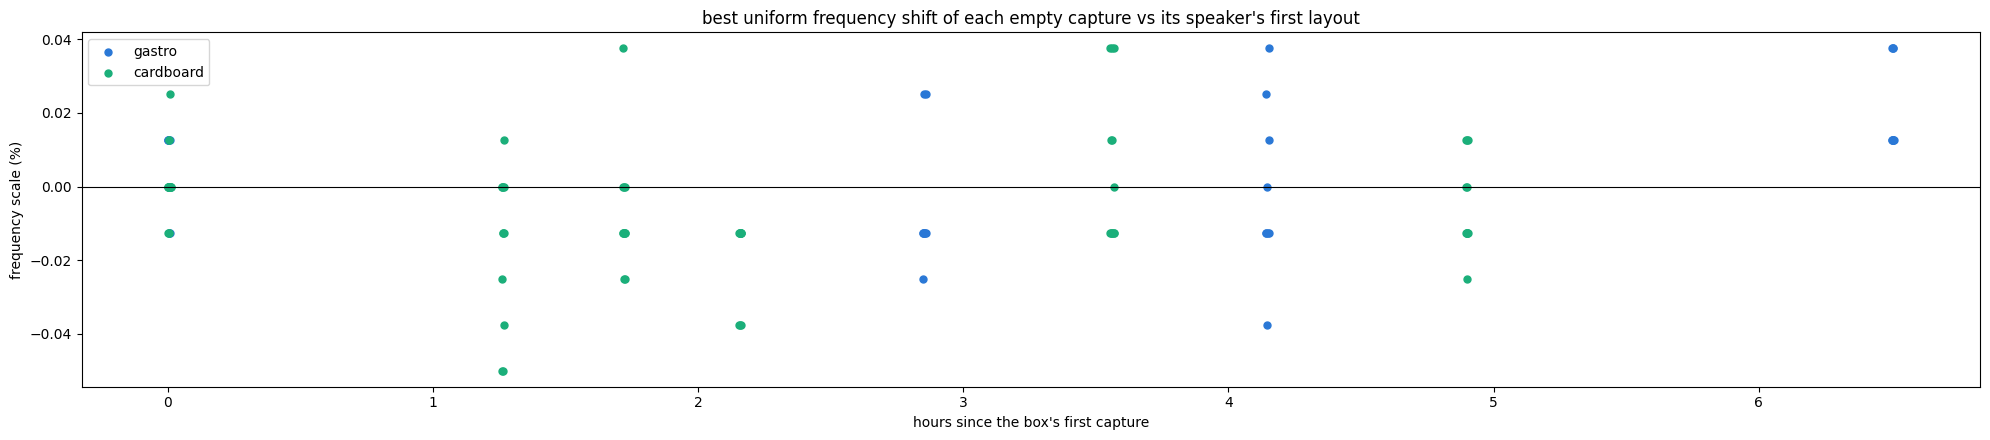

In [8]:
f = fr[inband]; mid_f = (f > 110) & (f < 990)
def full_db(d):   # Tukey |X| at full resolution, dB: (100, 1170, 2)
    x = sosfiltfilt(sos, np.load(d / "vibration/02_raw_shifts.npy"), axis=1)
    return (20 * np.log10(np.abs(np.fft.rfft(x * TUKEY[None, :, None], axis=1)[:, inband]) + 1e-12)).astype(np.float32)
e = df[df.obj == "empty"].reset_index(drop=True)
with ProcessPoolExecutor(24) as ex: F = np.stack(list(ex.map(full_db, e.dir)))                    # (empty captures, 100, 1170, 2)

# frequency scale per capture, against its speaker's first layout
ALPHAS = np.linspace(.985, 1.015, 241)
curve = F.mean((1, 3))
e["alpha"] = np.nan
for (box, spk), g in e.groupby(["box", "spk"]):
    ref = curve[g.index[g.layout == g.sort_values("t").layout.iloc[0]]].mean(0)
    for i in g.index: e.loc[i, "alpha"] = ALPHAS[np.argmax([np.corrcoef(np.interp(f * a, f, curve[i])[mid_f], ref[mid_f])[0, 1] for a in ALPHAS])]
Ff = np.stack([np.stack([np.stack([np.interp(f * e.alpha[i], f, F[i, l, :, c]) for c in range(2)], -1) for l in range(100)]) for i in range(len(e))])
STEPS = {"raw": F, "− frequency scale": Ff, "− frequency scale − laser level": Ff - Ff.mean((2, 3), keepdims=True)}

fig, ax = plt.subplots(figsize=(20, 4.5))
for box in BOXES:
    g = e[e.box == box]; ax.scatter(g.t / 60, 100 * (g.alpha - 1), c=COLORS[box], s=25, label=box)
ax.axhline(0, c="k", lw=.8)
ax.set(xlabel="hours since the box's first capture", ylabel="frequency scale (%)", title="best uniform frequency shift of each empty capture vs its speaker's first layout")
ax.legend()
plt.tight_layout()

rows = []
for box in BOXES:
    g = e[e.box == box]
    pr = [(i, j, g.layout[i] == g.layout[j]) for _, gg in g.groupby("spk") for n, i in enumerate(gg.index) for j in gg.index[n + 1:]]
    same = np.array([s for *_, s in pr])
    for name, Y in STEPS.items():
        d = np.array([0.5 * ((Y[i][:, mid_f] - Y[j][:, mid_f]) ** 2).mean() for i, j, _ in pr])
        rows.append(dict(box=box, step=name, R=d[same].mean(), hours_apart=d[~same].mean(), change=d[~same].mean() - d[same].mean()))
    Y = STEPS["− frequency scale − laser level"]
    ex = np.mean([0.5 * (Y[i] - Y[j]) ** 2 for i, j, s in pr if not s], 0) - np.mean([0.5 * (Y[i] - Y[j]) ** 2 for i, j, s in pr if s], 0)   # change per feature
    per_laser = np.sort(ex.mean((1, 2)))[::-1]
    lay = sorted(g.layout.unique(), key=lambda L: g.t[g.layout == L].mean())
    within, across = [], []
    for L in lay[1:]:
        dv = {}
        for s in sorted(g.spk.unique()):
            a, b = g.index[(g.spk == s) & (g.layout == lay[0])], g.index[(g.spk == s) & (g.layout == L)]
            if len(a) >= 2 and len(b) >= 2: dv[s] = [(Y[b[k]] - Y[a[k]]).ravel() for k in (0, 1)]
        within += [np.corrcoef(*dv[s])[0, 1] for s in dv]
        ks = sorted(dv); across += [np.corrcoef(dv[s][0], dv[t][1])[0, 1] for n, s in enumerate(ks) for t in ks[n + 1:]]
    rows[-1].update({"worst 10 lasers' share": per_laser[:10].sum() / per_laser.sum(), "agreement: same speaker": np.mean(within), "agreement: different speakers": np.mean(across)})
emp = pd.DataFrame(rows); emp["change removed"] = 1 - emp.change / emp.groupby("box").change.transform("first")
print(e.groupby("box").alpha.agg(lambda a: f"shift {100 * (a.mean() - 1):+.3f}% ± {100 * a.std():.3f}%"))
emp.set_index(["box", "step"]).round(3)

**Reading:** - **Not temperature.** The best uniform frequency shift is +0.004% (gastro) and −0.006% (cardboard), smaller than its own scatter (±0.02%), with no trend over 5-6 hours. Undoing it removes 1-3% of the change.
- **Not laser brightness.** Removing each laser's level as well removes 5-6% in total.
- **Not a few bad lasers.** The worst 10 of 100 lasers hold 12-13% of what is left (10% if perfectly even).
- **Different for each speaker.** Two captures from the same speaker agree on the change pattern (correlation 0.33 gastro, 0.60 cardboard), so it is real, but two different speakers barely agree (0.07, 0.11): about a fifth of it is shared. Temperature, lasers, camera or a uniform change of the box would be shared by every speaker.
- **What fits:** the geometry between the speakers and the box changing: the box nudged while placing objects, or the speaker rack bumped (all speakers sit on one frame on a stand, so a bump moves them together but changes each speaker's path into the box differently). This test can't tell the two apart; both are physical shifts of the same geometry.

# 9 Does Placing the Object Leak Into the Band?

nb96 §10: right after an object is put down, speaker 1 (recorded first, ~0.2 s later) sees the knock: +9 to +16 dB below 90 Hz. The 100 Hz band-pass removes that, but if any of it leaked above 100 Hz, speaker 1 would be (a) noisier at nearly the same spot, (b) worse at position (lower `(far − near) / near`), and (c) louder than the other speakers at object positions than at empty-box positions.

`near` = same layout, Δpos < 5%; `far` = Δpos ≥ 0.3; mean over objects.

In [9]:
def pair_gamma_bands(X, I, J, chunk=2000):   # per pair, per band: ½ (x_i − x_j)², averaged over lasers and axes -> (pairs, 117)
    return np.concatenate([(0.5 * (X[I[k:k + chunk]] - X[J[k:k + chunk]]) ** 2).reshape(-1, 100, 117, 2).mean((1, 3)) for k in range(0, len(I), chunk)])
def in_ranges(v): return {f"{lo}-{hi}": v[(fb >= lo) & (fb < hi)].mean() for lo, hi in RANGES} | {"all": v.mean()}

o = pairs[pairs.obj != "empty"]
o = pd.concat([o[(o.dpos < .05) & o.same_layout].assign(kind="near"), o[o.dpos >= .3].assign(kind="far")])
o = o.sample(frac=1, random_state=0).groupby(["box", "obj", "spk", "kind"]).head(1500)
G = pair_gamma_bands(DB, o.i.to_numpy(), o.j.to_numpy())
rows = [dict(box=box, obj=obj, spk=spk, kind=kind, **in_ranges(G[np.flatnonzero(((o.box == box) & (o.obj == obj) & (o.spk == spk) & (o.kind == kind)).to_numpy())].mean(0)))
        for (box, obj, spk, kind), _ in o.groupby(["box", "obj", "spk", "kind"])]
t = pd.DataFrame(rows).groupby(["box", "kind", "spk"]).mean(numeric_only=True)
ratio = (t.xs("far", level="kind") - t.xs("near", level="kind")) / t.xs("near", level="kind")

lv = DB.reshape(len(df), 100, 117, 2).mean((1, 3))
lvl = []
for (box, kind, pos), g in df.assign(kind=np.where(df.obj == "empty", "empty", "object")).groupby(["box", "kind", "pos"]):
    if 1 in g.spk.values and len(g) >= 3:
        lvl.append(dict(box=box, kind=kind, **in_ranges(lv[g.index[g.spk == 1]].mean(0) - lv[g.index[g.spk != 1]].mean(0))))
print("γ near (same layout, Δpos < 5%), dB²:"); display(t.xs("near", level="kind").unstack(0).round(2))
print("signal / near-floor = (far − near) / near:"); display(ratio.unstack(0).round(2))
print("speaker-1 level minus the other speakers' (dB), same position:")
pd.DataFrame(lvl).groupby(["box", "kind"]).mean().round(2)

γ near (same layout, Δpos < 5%), dB²:


100-150          150-300          300-700         700-1000         \
box cardboard gastro cardboard gastro cardboard gastro cardboard gastro   
spk                                                                       
1        1.99   0.80      1.45   1.31      2.81   1.65      3.51   2.20   
3        0.90   1.87      0.70   1.26      1.06   1.56      2.05   1.48   
5        0.98    NaN      0.59    NaN      1.01    NaN      2.27    NaN   
7        1.60   1.27      0.68   1.15      1.39   1.80      2.11   1.95   

          all         
box cardboard gastro  
spk                   
1        2.77   1.73  
3        1.32   1.50  
5        1.36    NaN  
7        1.52   1.71

signal / near-floor = (far − near) / near:


100-150          150-300          300-700         700-1000         \
box cardboard gastro cardboard gastro cardboard gastro cardboard gastro   
spk                                                                       
1        1.64   2.93      1.85   1.50      2.04   1.80      2.18   1.67   
3        2.07   2.06      1.86   1.35      1.74   1.45      1.64   1.74   
5        1.33    NaN      2.52    NaN      1.67    NaN      1.61    NaN   
7        1.48   1.80      2.13   1.43      1.88   1.59      2.13   1.72   

          all         
box cardboard gastro  
spk                   
1        2.07   1.74  
3        1.71   1.57  
5        1.69    NaN  
7        1.99   1.63

speaker-1 level minus the other speakers' (dB), same position:


100-150  150-300  300-700  700-1000   all
box       kind                                             
cardboard empty     -3.37    -4.04    -4.73     -2.25 -3.72
          object    -3.57    -4.13    -4.35     -2.26 -3.57
gastro    empty      0.53     1.05     0.56     -0.73  0.21
          object     0.72     1.01     0.85     -0.71  0.35

**Reading:** - **No leak.** In gastro, speaker 1 is no noisier at nearly the same spot (1.73 dB² vs 1.50-1.71) and is no worse at position (1.74 vs 1.57-1.63).
- In cardboard, speaker 1 differs ~2× more than the others in near **and** far pairs (2.77 vs 1.32-1.52 near), so its signal-to-floor ratio is no worse (2.07 vs 1.69-1.99). It is ~3.6 dB quieter in this box, which makes its dB values noisier overall.
- **Speaker 1's level relative to the other speakers** is the same at object positions as at empty positions (cardboard −3.57 vs −3.72 dB; gastro +0.35 vs +0.21): no extra energy where an object was just put down.
- So the placement knock stays below 90 Hz, where the band-pass removes it.

# 10 Scoring Preprocessing Candidates

Each candidate is a transform of `|X|` followed by the per-capture normalization src7 applies (`std`: `x / std(x)`; for log features `z`: `(x − mean) / std`). Per feature, the score is

```
r = S / N              # signal over "the same spot, recorded again", per feature
```

A fixed per-feature gain (deconvolution, a fixed weighting) does not change `r`: the model's first layer can learn any fixed gain. Only transforms that change a feature's signal-to-nuisance ratio move it: the window, compression, and normalizations that depend on the capture. The table reports the median `r` over features and the equal-weight ratio `ΣS / ΣN` (what a distance over all features, like the probe in nb100, sees).

The last column is the trained in-distribution IoU (mean over the candle/cube/soap/vase splits, last epoch) where a src7 run exists, to check whether the score agrees with training.

In [10]:
def std_norm(x): return x / x.std((1, 2, 3), keepdims=True)
def z_norm(x): return (x - x.mean((1, 2, 3), keepdims=True)) / x.std((1, 2, 3), keepdims=True)
T = MAG["tukey"]
CANDIDATES = {
    "hann |X|":                  lambda: std_norm(MAG["hann"]),                                          # src7 --window hann
    "tukey |X|":                 lambda: std_norm(T),                                                    # src7 --window tukey
    "tukey |X|^0.5":             lambda: std_norm(T ** .5),
    "tukey log|X|":              lambda: z_norm(np.log(T)),
    "tukey |X| / laser rms":     lambda: std_norm(T / np.sqrt((T ** 2).mean((2, 3), keepdims=True))),    # removes each laser's gain (nb53 β_n)
    "tukey log|X| − laser mean": lambda: z_norm(np.log(T) - np.log(T).mean((2, 3), keepdims=True)),
}
RUNS = {("gastro", "hann |X|"): "s7-gast-hann-3k", ("gastro", "tukey |X|"): "s7-gast-tukey-3k",
        ("cardboard", "hann |X|"): "s7-card-hann-3k", ("cardboard", "tukey |X|"): "s7-card-tukey-3k"}

def trained_iou(run, box):   # mean over the id splits of their mean IoU at epoch 3000; nan if the run isn't finished
    fs = [list((REPO / "runs" / run / "outputs_history" / "eval" / box / s).glob("ep3000-*.pt")) for s in ("candle", "cube", "soap-dispenser", "vase")]
    if not all(fs): return np.nan
    return np.mean([torch.cat([torch.load(f, weights_only=False)["metrics"]["iou"] for f in f_]).mean().item() for f_ in fs])

rows = []
for name, make in CANDIDATES.items():
    X = make().reshape(len(df), -1)
    for box in BOXES:
        r = budget(X, box)
        rows.append({"box": box, "candidate": name, "median r": np.median(r["S"] / r["N"]), "ΣS / ΣN": r["S"].sum() / r["N"].sum(),
                     "(N − R) / R": (r["N"] - r["R"]).sum() / r["R"].sum(), "trained id IoU": trained_iou(RUNS[box, name], box) if (box, name) in RUNS else np.nan})
    del X
score = pd.DataFrame(rows).set_index(["box", "candidate"])
score.round(3)

,,median r,ΣS / ΣN,(N − R) / R,trained id IoU
box,candidate,,,,
gastro,hann |X|,1.039,1.439,1.994,0.577
cardboard,hann |X|,1.153,0.615,2.190,0.444
gastro,tukey |X|,1.263,1.467,2.335,0.573
cardboard,tukey |X|,1.412,0.649,3.037,NaN
gastro,tukey |X|^0.5,1.223,1.326,2.111,NaN
cardboard,tukey |X|^0.5,1.323,1.065,1.608,NaN
gastro,tukey log|X|,1.180,1.173,1.979,NaN
cardboard,tukey log|X|,1.156,1.171,1.151,NaN
gastro,tukey |X| / laser rms,1.285,1.512,2.296,NaN


**Reading:** - **Tukey beats Hann** on the per-feature score in both boxes (median r +22% in both).
- **No candidate removes the later-layout term.** Dividing out each laser's gain (`/ laser rms`, `− laser mean`) barely moves either score (≤ 0.02 median r), as section 8 predicts: what changes is the speaker-box geometry, which no per-capture or per-laser gain fixes.
- **Compression helps cardboard's equal-weight score.** `|X|^0.5` and `log|X|` raise ΣS/ΣN from 0.65 to 1.07-1.17 and cut `(N − R)/R` from 3.0 to 1.15-1.6: in linear magnitude, cardboard's largest features (the resonance peaks) are also the most unstable, and compression shrinks them. The per-feature median r doesn't move that way, because a fixed weighting can't change a feature's own ratio.
- **Which score to trust:** gastro Hann → Tukey moved median r +22% but ΣS/ΣN only +2%, and trained IoU didn't move (0.577 → 0.573). On this one point, the equal-weight score agreed with training. For cardboard the two predict +22% vs +6%; `s7-card-tukey-3k` (still training) is the second check.

# 11 Conclusion

| | gastro | cardboard |
|---|---|---|
| repeat noise R, empty back-to-back (dB²) | 0.63 | 1.13 |
| same object, nearly the same spot, recorded again: N | 1.98 (3.1× R) | 2.45 (2.2× R) |
| empty box, hours apart, above R | 1.20 | 2.86 |
| signal S, object moved ≥ 0.3 of the box | 2.35 (1.19× N) | 2.88 (1.18× N) |
| random orientation, extra at the same spot (cardboard cube) | | +0.6-0.7 |

1. **Repeat noise is the smallest term.** Re-recording the same object at nearly the same spot differs 2-3× as much as recording twice in a row, and moving the object across the box adds only ~1.2× that floor. The Tukey window (nb100) improved the spectral estimate, which mostly shrinks `R`, the smallest term.
2. **The biggest term comes between layouts.** At every distance, captures from a later layout differ more than captures from the same layout, for round objects as much as for the cube and soap dispenser.
3. **What changes is the speaker-box geometry.** The empty box changes over hours with nothing placed in it, differently for each speaker, with no frequency shift (not temperature), no laser-level change, and not in a few lasers. Box nudges during placement and bumps to the speaker rack both fit.
4. **Orientation adds to it** (+0.6-0.7 dB² for a random cube pose, about a fifth of the cube's signal) but is not the main cause.
5. **Placing the object doesn't leak into the band**: speaker 1 is no worse; the knock stays below 90 Hz.
6. **The best band is 700-1000 Hz** (S / N 1.4 in both boxes); cardboard below 300 Hz is mostly floor.

**What would help:**
- *Rig:* clamp the box and the speaker rack; mark orientations on the box floor; a short empty-box capture per speaker every K positions to track the geometry.
- *Model:* combine the 4 speakers, since each sees the geometry change differently. First test: average the existing model's predictions over a position's 4 speakers.
- *Preprocessing:* compression (√ or log) halves cardboard's later-layout share in the equal-weight score; no gain normalization helps. Don't use corrections that remove slow changes over time: the recordings are scans (section 2).